# Attention-based Slice-aware Refiner Training

**Architecture**: Cross-attention based refiner
- Query: Center draft (개선 대상)
- Key/Value: High-quality neighbor drafts (참조)
- CT condition

**Training**: End-to-end with GT supervision
- L1 + LPIPS + Perceptual loss
## 1. Setup


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict
import json

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision.models as models

# LPIPS
import lpips

print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

import warnings
warnings.filterwarnings('ignore')




/home/youkyoung/.conda/envs/med/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu124
CUDA Available: True


In [2]:
CFG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    "seed": 42,
    
    # Paths
    "data_root": "../data/processed_with_skullstrip",
    "draft_dir": "./draft_results",
    "quality_predictor_path": "./quality_comparison/best_quality_predictor.pt",
    "save_dir": "./ckpt_attention_refiner",
    
    # Model
    "img_size": 256,
    "context_window": 3,  # ±3 slices
    "quality_threshold_factor": 1.0,  # Mean + 1σ
    
    # Training
    "train_ratio": 0.9,
    "batch_size": 2,
    "num_workers": 4,
    "epochs": 50,
    "lr": 1e-4,
    "weight_decay": 1e-5,
    "grad_clip": 1.0,
    "use_mixed_precision": True,
    
    # Loss weights
    "w_l1": 0.5,
    "w_lpips": 0.3,
    "w_perceptual": 0.2,
    
    # Save
    "save_every": 5,
    "val_every": 1,
}

torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])

Path(CFG["save_dir"]).mkdir(parents=True, exist_ok=True)

print("="*80)
print("Configuration")
print("="*80)
for k, v in CFG.items():
    print(f"  {k:30s}: {v}")
print("="*80)


# ## 2. Quality Predictor Loading



Configuration
  device                        : cuda
  seed                          : 42
  data_root                     : ../data/processed_with_skullstrip
  draft_dir                     : ./draft_results
  quality_predictor_path        : ./quality_comparison/best_quality_predictor.pt
  save_dir                      : ./ckpt_attention_refiner
  img_size                      : 256
  context_window                : 3
  quality_threshold_factor      : 1.0
  train_ratio                   : 0.9
  batch_size                    : 2
  num_workers                   : 4
  epochs                        : 50
  lr                            : 0.0001
  weight_decay                  : 1e-05
  grad_clip                     : 1.0
  use_mixed_precision           : True
  w_l1                          : 0.5
  w_lpips                       : 0.3
  w_perceptual                  : 0.2
  save_every                    : 5
  val_every                     : 1


In [3]:
print("\n" + "="*80)
print("Loading Quality Predictor")
print("="*80)

# Load quality predictor
class QualityPredictor(nn.Module):
    """Trained quality predictor"""
    def __init__(self, backbone='resnet50'):
        super().__init__()
        
        if backbone == 'resnet50':
            resnet = models.resnet50(pretrained=True)
            self.features = nn.Sequential(*list(resnet.children())[:-2])
            feat_dim = 2048
        
        for name, param in self.features.named_parameters():
            if 'layer4' not in name:
                param.requires_grad = False
        
        self.quality_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(feat_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        x = x.repeat(1, 3, 1, 1) if x.size(1) == 1 else x
        feat = self.features(x)
        quality = self.quality_head(feat)
        return quality.squeeze(-1)


# Load checkpoint
quality_predictor = QualityPredictor(backbone='resnet50').to(CFG["device"])
checkpoint = torch.load(CFG["quality_predictor_path"], map_location=CFG["device"])
quality_predictor.load_state_dict(checkpoint['model_state_dict'])
quality_predictor.eval()

# Freeze
for param in quality_predictor.parameters():
    param.requires_grad = False

print(f"✓ Quality predictor loaded")
print(f"  Correlation with LPIPS: {checkpoint['val_corr']:.4f}")
print("="*80)


# ## 3. Dataset




Loading Quality Predictor
✓ Quality predictor loaded
  Correlation with LPIPS: 0.9860


In [4]:
def load_image(path, size=256):
    """Load and preprocess image to [0, 1]"""
    img = Image.open(path).convert('L')
    img = img.resize((size, size), Image.BICUBIC)
    return np.array(img, dtype=np.float32) / 255.0


class RefinerDataset(Dataset):
    """
    Dataset for refiner training
    Returns center draft + high-quality neighbors + CT + GT
    """
    
    def __init__(self, data_root, draft_dir, quality_predictor, 
                 mode='train', train_ratio=0.9, img_size=256,
                 context_window=3, quality_threshold_factor=1.0, device='cuda'):
        self.data_root = Path(data_root)
        self.draft_dir = Path(draft_dir)
        self.quality_predictor = quality_predictor
        self.mode = mode
        self.img_size = img_size
        self.context_window = context_window
        self.device = device
        
        # Collect samples and compute quality scores
        self.samples = self._collect_samples(train_ratio)
        
        # Compute quality threshold
        self._compute_quality_threshold(quality_threshold_factor)
        
        print(f"  {mode}: {len(self.samples)} samples")
        print(f"  Quality threshold (Mean + {quality_threshold_factor}σ): {self.quality_threshold:.4f}")
    
    def _collect_samples(self, train_ratio):
        """Collect all samples and group by patient"""
        patient_slices = defaultdict(list)
        
        for group in ['bleed', 'non_bleed']:
            group_dir = self.data_root / group
            if not group_dir.exists():
                continue
            
            for patient_dir in sorted(group_dir.iterdir()):
                if not patient_dir.is_dir():
                    continue
                
                patient = patient_dir.name
                ct_dir = patient_dir / 'ct_axial'
                mri_dir = patient_dir / 'mri_b0_axial'
                
                if not (ct_dir.exists() and mri_dir.exists()):
                    continue
                
                # Match CT-MRI
                ct_files = sorted(ct_dir.glob('*.png'))
                mri_files = sorted(mri_dir.glob('*.png'))
                
                ct_dict = {f.stem: f for f in ct_files}
                mri_dict = {f.stem: f for f in mri_files}
                common = sorted(set(ct_dict.keys()) & set(mri_dict.keys()))
                
                for i, slice_name in enumerate(common):
                    draft_file = self.draft_dir / group / patient / f"{slice_name}.png"
                    if not draft_file.exists():
                        continue
                    
                    patient_slices[patient].append({
                        'group': group,
                        'patient': patient,
                        'slice_idx': i,
                        'slice_name': slice_name,
                        'draft_path': str(draft_file),
                        'ct_path': str(ct_dict[slice_name]),
                        'gt_path': str(mri_dict[slice_name]),
                    })
        
        # Train/val split by patient
        patients = sorted(patient_slices.keys())
        n_train = int(len(patients) * train_ratio)
        train_patients = set(patients[:n_train])
        
        samples = []
        for patient, slices in patient_slices.items():
            if (self.mode == 'train' and patient in train_patients) or \
               (self.mode == 'val' and patient not in train_patients):
                samples.extend(slices)
        
        return samples
    
    def _compute_quality_threshold(self, factor):
        """Compute quality threshold from all training drafts"""
        print(f"\n  Computing quality threshold...")
        
        all_qualities = []
        
        with torch.no_grad():
            for sample in tqdm(self.samples[:min(1000, len(self.samples))], 
                             desc="  Sampling qualities"):
                draft = load_image(sample['draft_path'], self.img_size)
                draft_t = torch.from_numpy(draft).unsqueeze(0).unsqueeze(0).float()
                draft_t = draft_t * 2 - 1
                draft_t = draft_t.to(self.device)
                
                quality = self.quality_predictor(draft_t)
                all_qualities.append(quality.item())
        
        all_qualities = np.array(all_qualities)
        mean_quality = all_qualities.mean()
        std_quality = all_qualities.std()
        
        self.quality_threshold = mean_quality + factor * std_quality
        self.quality_mean = mean_quality
        self.quality_std = std_quality
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        patient = sample['patient']
        slice_idx = sample['slice_idx']
        
        # Get all slices for this patient
        patient_slices = [s for s in self.samples if s['patient'] == patient]
        patient_slices.sort(key=lambda x: x['slice_idx'])
        
        total_slices = len(patient_slices)
        
        # Context window [slice_idx - window, slice_idx + window]
        start = max(0, slice_idx - self.context_window)
        end = min(total_slices, slice_idx + self.context_window + 1)
        
        # Load center
        center_draft = load_image(sample['draft_path'], self.img_size)
        center_ct = load_image(sample['ct_path'], self.img_size)
        center_gt = load_image(sample['gt_path'], self.img_size)
        
        # Load neighbors and compute qualities
        neighbor_drafts = []
        neighbor_qualities = []
        
        for i in range(start, end):
            if i == slice_idx:  # Skip center
                continue
            
            neighbor_draft = load_image(patient_slices[i]['draft_path'], self.img_size)
            neighbor_drafts.append(neighbor_draft)
            
            # Compute quality
            with torch.no_grad():
                draft_t = torch.from_numpy(neighbor_draft).unsqueeze(0).unsqueeze(0).float()
                draft_t = draft_t * 2 - 1
                draft_t = draft_t.to(self.device)
                quality = self.quality_predictor(draft_t)
                neighbor_qualities.append(quality.item())
        
        # Select high-quality neighbors (above threshold)
        if len(neighbor_qualities) > 0:
            neighbor_qualities = np.array(neighbor_qualities)
            high_quality_mask = neighbor_qualities >= self.quality_threshold
            
            if high_quality_mask.sum() > 0:
                selected_neighbors = [neighbor_drafts[i] for i in range(len(neighbor_drafts)) 
                                    if high_quality_mask[i]]
                selected_qualities = neighbor_qualities[high_quality_mask]
            else:
                # If no high-quality, use top 3
                top_k = min(3, len(neighbor_qualities))
                top_indices = np.argsort(neighbor_qualities)[-top_k:]
                selected_neighbors = [neighbor_drafts[i] for i in top_indices]
                selected_qualities = neighbor_qualities[top_indices]
        else:
            selected_neighbors = []
            selected_qualities = np.array([])
        
        # Pad to 5 neighbors (max)
        max_neighbors = 5
        while len(selected_neighbors) < max_neighbors:
            selected_neighbors.append(np.zeros((self.img_size, self.img_size), dtype=np.float32))
            selected_qualities = np.append(selected_qualities, 0.0)
        
        # Take top 5 if more
        if len(selected_neighbors) > max_neighbors:
            top_indices = np.argsort(selected_qualities)[-max_neighbors:]
            selected_neighbors = [selected_neighbors[i] for i in top_indices]
            selected_qualities = selected_qualities[top_indices]
        
        # To tensor [-1, 1]
        center_draft_t = torch.from_numpy(center_draft).unsqueeze(0).float() * 2 - 1
        center_ct_t = torch.from_numpy(center_ct).unsqueeze(0).float() * 2 - 1
        center_gt_t = torch.from_numpy(center_gt).unsqueeze(0).float() * 2 - 1
        
        neighbors_t = torch.stack([
            torch.from_numpy(n).unsqueeze(0).float() * 2 - 1
            for n in selected_neighbors
        ])  # [5, 1, H, W]
        
        qualities_t = torch.from_numpy(selected_qualities).float()
        
        return {
            'center_draft': center_draft_t,
            'center_ct': center_ct_t,
            'center_gt': center_gt_t,
            'neighbors': neighbors_t,
            'neighbor_qualities': qualities_t,
            'patient': sample['patient'],
            'slice_name': sample['slice_name'],
        }


print("\n✓ RefinerDataset defined")





✓ RefinerDataset defined


In [5]:
# In[5]


print("\n" + "="*80)
print("Creating Datasets")
print("="*80)

# Fix CUDA multiprocessing issue
import torch.multiprocessing as mp
try:
    mp.set_start_method('spawn', force=True)
except RuntimeError:
    pass

train_dataset = RefinerDataset(
    CFG["data_root"],
    CFG["draft_dir"],
    quality_predictor,
    mode='train',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"],
    context_window=CFG["context_window"],
    quality_threshold_factor=CFG["quality_threshold_factor"],
    device=CFG["device"]
)

val_dataset = RefinerDataset(
    CFG["data_root"],
    CFG["draft_dir"],
    quality_predictor,
    mode='val',
    train_ratio=CFG["train_ratio"],
    img_size=CFG["img_size"],
    context_window=CFG["context_window"],
    quality_threshold_factor=CFG["quality_threshold_factor"],
    device=CFG["device"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=0,  # ✅ Changed from 4 to 0
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=0,  # ✅ Changed from 4 to 0
    pin_memory=True
)

print(f"\n✓ Datasets created")
print(f"  Train: {len(train_dataset)} samples")
print(f"  Val:   {len(val_dataset)} samples")
print("="*80)


Creating Datasets

  Computing quality threshold...


  Sampling qualities: 100%|██████████| 1000/1000 [00:05<00:00, 195.13it/s]


  train: 5289 samples
  Quality threshold (Mean + 1.0σ): 0.8349

  Computing quality threshold...


  Sampling qualities: 100%|██████████| 589/589 [00:02<00:00, 203.39it/s]

  val: 589 samples
  Quality threshold (Mean + 1.0σ): 0.8421

✓ Datasets created
  Train: 5289 samples
  Val:   589 samples


In [6]:
class ConvNeXtBlock(nn.Module):
    """ConvNeXt block for feature extraction"""
    def __init__(self, channels, expansion=4):
        super().__init__()
        self.dwconv = nn.Conv2d(channels, channels, 7, 1, 3, groups=channels)
        self.norm = nn.LayerNorm(channels)
        self.pwconv1 = nn.Linear(channels, expansion * channels)
        self.act = nn.GELU()
        self.pwconv2 = nn.Linear(expansion * channels, channels)
        self.gamma = nn.Parameter(torch.ones(channels) * 1e-6)
    
    def forward(self, x):
        residual = x
        x = self.dwconv(x)
        x = x.permute(0, 2, 3, 1)  # [B, C, H, W] -> [B, H, W, C]
        x = self.norm(x)
        x = self.pwconv1(x)
        x = self.act(x)
        x = self.pwconv2(x)
        x = self.gamma * x
        x = x.permute(0, 3, 1, 2)  # [B, H, W, C] -> [B, C, H, W]
        return residual + x


class FeatureEncoder(nn.Module):
    """Feature encoder with skip connections"""
    def __init__(self, in_channels=1, base_channels=64):
        super().__init__()
        
        # Encoder with skip connections
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, base_channels, 3, 1, 1),
            nn.GroupNorm(8, base_channels),
            nn.GELU(),
            ConvNeXtBlock(base_channels)
        )
        
        self.enc2 = nn.Sequential(
            nn.Conv2d(base_channels, base_channels * 2, 3, 2, 1),
            nn.GroupNorm(8, base_channels * 2),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 2)
        )
        
        self.enc3 = nn.Sequential(
            nn.Conv2d(base_channels * 2, base_channels * 4, 3, 2, 1),
            nn.GroupNorm(8, base_channels * 4),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 4)
        )
    
    def forward(self, x):
        e1 = self.enc1(x)  # [B, 64, 256, 256]
        e2 = self.enc2(e1)  # [B, 128, 128, 128]
        e3 = self.enc3(e2)  # [B, 256, 64, 64]
        
        return e3, [e1, e2]  # Features + skips


class CrossAttentionFusion(nn.Module):
    """
    Cross-attention to fuse neighbor information
    Query: Center draft features
    Key/Value: Neighbor draft features
    """
    def __init__(self, embed_dim=256, num_heads=8, dropout=0.1):
        super().__init__()
        
        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )
        
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * 4, embed_dim),
            nn.Dropout(dropout)
        )
    
    def forward(self, query, key_value, key_padding_mask=None):
        """
        Args:
            query: [B, N_q, C] - center features
            key_value: [B, N_kv, C] - neighbor features
            key_padding_mask: [B, N_kv] - True for padding positions
        """
        # Self-attention with residual
        attn_output, attn_weights = self.attention(
            query, key_value, key_value,
            key_padding_mask=key_padding_mask
        )
        query = self.norm1(query + attn_output)
        
        # FFN with residual
        ffn_output = self.ffn(query)
        query = self.norm2(query + ffn_output)
        
        return query, attn_weights


class AttentionRefiner(nn.Module):
    """
    Attention-based slice-aware refiner
    
    Query: Center draft (what to improve?)
    Key/Value: High-quality neighbors (how good parts look like?)
    """
    def __init__(self, base_channels=64):
        super().__init__()
        
        # Encoders
        self.center_encoder = FeatureEncoder(in_channels=1, base_channels=base_channels)
        self.neighbor_encoder = FeatureEncoder(in_channels=1, base_channels=base_channels)
        self.ct_encoder = FeatureEncoder(in_channels=1, base_channels=base_channels)
        
        feat_channels = base_channels * 4  # 256
        
        # Cross-attention
        self.cross_attention = CrossAttentionFusion(
            embed_dim=feat_channels,
            num_heads=8,
            dropout=0.1
        )
        
        # Feature fusion
        self.fusion = nn.Sequential(
            nn.Conv2d(feat_channels * 2, feat_channels, 3, 1, 1),  # center + attn
            nn.GroupNorm(8, feat_channels),
            nn.GELU(),
            ConvNeXtBlock(feat_channels),
            nn.Conv2d(feat_channels, feat_channels, 3, 1, 1),
            nn.GroupNorm(8, feat_channels),
            nn.GELU(),
        )
        
        # Add CT condition
        self.ct_fusion = nn.Sequential(
            nn.Conv2d(feat_channels * 2, feat_channels, 3, 1, 1),
            nn.GroupNorm(8, feat_channels),
            nn.GELU(),
        )
        
        # Decoder with skip connections
        self.dec3 = nn.Sequential(
            nn.ConvTranspose2d(feat_channels, base_channels * 2, 2, 2),
            nn.GroupNorm(8, base_channels * 2),
            nn.GELU(),
            ConvNeXtBlock(base_channels * 2)
        )
        
        self.dec2 = nn.Sequential(
            nn.Conv2d(base_channels * 4, base_channels * 2, 3, 1, 1),  # concat with skip
            nn.GroupNorm(8, base_channels * 2),
            nn.GELU(),
            nn.ConvTranspose2d(base_channels * 2, base_channels, 2, 2),
            nn.GroupNorm(8, base_channels),
            nn.GELU(),
            ConvNeXtBlock(base_channels)
        )
        
        self.dec1 = nn.Sequential(
            nn.Conv2d(base_channels * 2, base_channels, 3, 1, 1),  # concat with skip
            nn.GroupNorm(8, base_channels),
            nn.GELU(),
            ConvNeXtBlock(base_channels)
        )
        
        # Output
        self.out = nn.Conv2d(base_channels, 1, 1)
    
    def forward(self, center_draft, neighbors, center_ct, neighbor_qualities=None):
        """
        Args:
            center_draft: [B, 1, H, W]
            neighbors: [B, N, 1, H, W] - N neighbors
            center_ct: [B, 1, H, W]
            neighbor_qualities: [B, N] - quality scores (optional)
        
        Returns:
            refined: [B, 1, H, W]
            attn_weights: [B, num_heads, N_q, N_kv]
        """
        B, N, _, H, W = neighbors.shape
        
        # Encode center
        center_feat, center_skips = self.center_encoder(center_draft)  # [B, 256, 64, 64]
        
        # Encode CT
        ct_feat, _ = self.ct_encoder(center_ct)
        
        # Encode neighbors
        neighbors_flat = neighbors.view(B * N, 1, H, W)
        neighbor_feat, _ = self.neighbor_encoder(neighbors_flat)  # [B*N, 256, 64, 64]
        neighbor_feat = neighbor_feat.view(B, N, *neighbor_feat.shape[1:])  # [B, N, 256, 64, 64]
        
        # Prepare for attention: [B, C, H, W] -> [B, H*W, C]
        _, C, fH, fW = center_feat.shape
        
        query = center_feat.flatten(2).permute(0, 2, 1)  # [B, fH*fW, C]
        key_value = neighbor_feat.flatten(3).permute(0, 1, 3, 2)  # [B, N, fH*fW, C]
        key_value = key_value.reshape(B, N * fH * fW, C)  # [B, N*fH*fW, C]
        
        # Create padding mask for zero-quality neighbors
        if neighbor_qualities is not None:
            # [B, N] -> [B, N*fH*fW]
            padding_mask = (neighbor_qualities == 0).unsqueeze(-1).expand(-1, -1, fH * fW)
            padding_mask = padding_mask.reshape(B, N * fH * fW)
        else:
            padding_mask = None
        
        # Cross-attention
        attn_output, attn_weights = self.cross_attention(
            query, key_value, key_padding_mask=padding_mask
        )  # [B, fH*fW, C]
        
        # Reshape back
        attn_output = attn_output.permute(0, 2, 1).reshape(B, C, fH, fW)
        
        # Fuse center + attention
        fused = self.fusion(torch.cat([center_feat, attn_output], dim=1))
        
        # Add CT condition
        fused = self.ct_fusion(torch.cat([fused, ct_feat], dim=1))
        
        # Decode with skip connections
        d3 = self.dec3(fused)  # [B, 128, 128, 128]
        d2 = self.dec2(torch.cat([d3, center_skips[1]], dim=1))  # [B, 64, 256, 256]
        d1 = self.dec1(torch.cat([d2, center_skips[0]], dim=1))  # [B, 64, 256, 256]
        
        # Output
        refined = self.out(d1)  # [B, 1, 256, 256]
        
        return refined, attn_weights


print("✓ AttentionRefiner model defined")




✓ AttentionRefiner model defined


In [7]:
# Initialize model
model = AttentionRefiner(base_channels=64).to(CFG["device"])

print(f"\n✓ Model initialized")
print(f"  Total params: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


# ## 5. Loss Functions




✓ Model initialized
  Total params: 8,279,489
  Trainable params: 8,279,489


In [8]:
print("\n" + "="*80)
print("Initializing Loss Functions")
print("="*80)

# LPIPS
lpips_loss_fn = lpips.LPIPS(net='alex', verbose=False).to(CFG["device"])
lpips_loss_fn.eval()
for param in lpips_loss_fn.parameters():
    param.requires_grad = False

# Perceptual loss (VGG features)
class PerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(pretrained=True).features[:23]  # Up to conv4_3
        self.vgg = vgg.eval()
        for param in self.vgg.parameters():
            param.requires_grad = False
    
    def forward(self, pred, target):
        # Convert grayscale to RGB
        pred_rgb = pred.repeat(1, 3, 1, 1)
        target_rgb = target.repeat(1, 3, 1, 1)
        
        # Extract features
        pred_feat = self.vgg(pred_rgb)
        target_feat = self.vgg(target_rgb)
        
        # L1 loss on features
        loss = F.l1_loss(pred_feat, target_feat)
        return loss

perceptual_loss_fn = PerceptualLoss().to(CFG["device"])

print("✓ Loss functions initialized")
print("  - L1 loss")
print("  - LPIPS (AlexNet)")
print("  - Perceptual (VGG16 conv4_3)")
print("="*80)


# ## 6. Training Functions




Initializing Loss Functions
✓ Loss functions initialized
  - L1 loss
  - LPIPS (AlexNet)
  - Perceptual (VGG16 conv4_3)


In [9]:
def train_epoch(model, loader, optimizer, scaler, epoch, cfg, device):
    """Train for one epoch"""
    model.train()
    
    losses = defaultdict(list)
    
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}/{cfg['epochs']}")
    
    for batch in pbar:
        center_draft = batch['center_draft'].to(device)
        neighbors = batch['neighbors'].to(device)
        center_ct = batch['center_ct'].to(device)
        center_gt = batch['center_gt'].to(device)
        neighbor_qualities = batch['neighbor_qualities'].to(device)
        
        optimizer.zero_grad()
        
        if cfg["use_mixed_precision"]:
            with autocast():
                # Forward
                refined, attn_weights = model(
                    center_draft, neighbors, center_ct, neighbor_qualities
                )
                
                # Losses
                loss_l1 = F.l1_loss(refined, center_gt)
                
                # LPIPS (needs 3 channels)
                refined_3ch = refined.repeat(1, 3, 1, 1)
                gt_3ch = center_gt.repeat(1, 3, 1, 1)
                loss_lpips = lpips_loss_fn(refined_3ch, gt_3ch).mean()
                
                # Perceptual
                loss_perceptual = perceptual_loss_fn(refined, center_gt)
                
                # Total loss
                loss = (
                    cfg["w_l1"] * loss_l1 +
                    cfg["w_lpips"] * loss_lpips +
                    cfg["w_perceptual"] * loss_perceptual
                )
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(optimizer)
            scaler.update()
        else:
            # Forward
            refined, attn_weights = model(
                center_draft, neighbors, center_ct, neighbor_qualities
            )
            
            # Losses
            loss_l1 = F.l1_loss(refined, center_gt)
            
            refined_3ch = refined.repeat(1, 3, 1, 1)
            gt_3ch = center_gt.repeat(1, 3, 1, 1)
            loss_lpips = lpips_loss_fn(refined_3ch, gt_3ch).mean()
            
            loss_perceptual = perceptual_loss_fn(refined, center_gt)
            
            loss = (
                cfg["w_l1"] * loss_l1 +
                cfg["w_lpips"] * loss_lpips +
                cfg["w_perceptual"] * loss_perceptual
            )
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            optimizer.step()
        
        # Log
        losses['total'].append(loss.item())
        losses['l1'].append(loss_l1.item())
        losses['lpips'].append(loss_lpips.item())
        losses['perceptual'].append(loss_perceptual.item())
        
        pbar.set_postfix({
            'loss': f"{loss.item():.4f}",
            'l1': f"{loss_l1.item():.4f}",
            'lpips': f"{loss_lpips.item():.4f}"
        })
    
    return {k: np.mean(v) for k, v in losses.items()}


@torch.no_grad()
def val_epoch(model, loader, epoch, cfg, device):
    """Validate for one epoch"""
    model.eval()
    
    losses = defaultdict(list)
    
    for batch in tqdm(loader, desc="Validation"):
        center_draft = batch['center_draft'].to(device)
        neighbors = batch['neighbors'].to(device)
        center_ct = batch['center_ct'].to(device)
        center_gt = batch['center_gt'].to(device)
        neighbor_qualities = batch['neighbor_qualities'].to(device)
        
        # Forward
        refined, attn_weights = model(
            center_draft, neighbors, center_ct, neighbor_qualities
        )
        
        # Losses
        loss_l1 = F.l1_loss(refined, center_gt)
        
        refined_3ch = refined.repeat(1, 3, 1, 1)
        gt_3ch = center_gt.repeat(1, 3, 1, 1)
        loss_lpips = lpips_loss_fn(refined_3ch, gt_3ch).mean()
        
        loss_perceptual = perceptual_loss_fn(refined, center_gt)
        
        loss = (
            cfg["w_l1"] * loss_l1 +
            cfg["w_lpips"] * loss_lpips +
            cfg["w_perceptual"] * loss_perceptual
        )
        
        losses['total'].append(loss.item())
        losses['l1'].append(loss_l1.item())
        losses['lpips'].append(loss_lpips.item())
        losses['perceptual'].append(loss_perceptual.item())
    
    return {k: np.mean(v) for k, v in losses.items()}


print("✓ Training functions defined")


# ## 7. Training Loop



✓ Training functions defined


In [10]:
print("\n" + "="*80)
print("Starting Training")
print("="*80)

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG["lr"],
    weight_decay=CFG["weight_decay"]
)

# Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CFG["epochs"],
    eta_min=1e-6
)

# Mixed precision scaler
scaler = GradScaler() if CFG["use_mixed_precision"] else None

# Training history
history = {
    'train_loss': [],
    'train_l1': [],
    'train_lpips': [],
    'train_perceptual': [],
    'val_loss': [],
    'val_l1': [],
    'val_lpips': [],
    'val_perceptual': [],
    'lr': []
}

best_val_loss = float('inf')

for epoch in range(CFG["epochs"]):
    # Train
    train_metrics = train_epoch(
        model, train_loader, optimizer, scaler, epoch, CFG, CFG["device"]
    )
    
    # Validation
    if (epoch + 1) % CFG["val_every"] == 0:
        val_metrics = val_epoch(
            model, val_loader, epoch, CFG, CFG["device"]
        )
    else:
        val_metrics = {k: 0.0 for k in train_metrics.keys()}
    
    # Scheduler step
    scheduler.step()
    
    # Log
    current_lr = optimizer.param_groups[0]['lr']
    
    history['train_loss'].append(train_metrics['total'])
    history['train_l1'].append(train_metrics['l1'])
    history['train_lpips'].append(train_metrics['lpips'])
    history['train_perceptual'].append(train_metrics['perceptual'])
    
    if (epoch + 1) % CFG["val_every"] == 0:
        history['val_loss'].append(val_metrics['total'])
        history['val_l1'].append(val_metrics['l1'])
        history['val_lpips'].append(val_metrics['lpips'])
        history['val_perceptual'].append(val_metrics['perceptual'])
    
    history['lr'].append(current_lr)
    
    print(f"\nEpoch {epoch+1}/{CFG['epochs']}")
    print(f"  Train - Loss: {train_metrics['total']:.4f}, "
          f"L1: {train_metrics['l1']:.4f}, "
          f"LPIPS: {train_metrics['lpips']:.4f}, "
          f"Perceptual: {train_metrics['perceptual']:.4f}")
    
    if (epoch + 1) % CFG["val_every"] == 0:
        print(f"  Val   - Loss: {val_metrics['total']:.4f}, "
              f"L1: {val_metrics['l1']:.4f}, "
              f"LPIPS: {val_metrics['lpips']:.4f}, "
              f"Perceptual: {val_metrics['perceptual']:.4f}")
    
    print(f"  LR: {current_lr:.6f}")
    
    # Save checkpoint
    if (epoch + 1) % CFG["save_every"] == 0:
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_metrics['total'],
            'val_loss': val_metrics['total'],
            'cfg': CFG,
        }
        
        checkpoint_path = Path(CFG["save_dir"]) / f"checkpoint_epoch_{epoch+1:03d}.pt"
        torch.save(checkpoint, checkpoint_path)
        print(f"  ✓ Checkpoint saved: {checkpoint_path}")
    
    # Save best model
    if (epoch + 1) % CFG["val_every"] == 0 and val_metrics['total'] < best_val_loss:
        best_val_loss = val_metrics['total']
        
        best_checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'val_loss': val_metrics['total'],
            'cfg': CFG,
        }
        
        best_path = Path(CFG["save_dir"]) / "best_refiner.pt"
        torch.save(best_checkpoint, best_path)
        print(f"  ✓ Best model saved: {best_path} (val_loss: {best_val_loss:.4f})")

print("\n" + "="*80)
print("Training Complete!")
print("="*80)
print(f"Best validation loss: {best_val_loss:.4f}")


# ## 8. Save Training History




Starting Training


Validation: 100%|██████████| 295/295 [00:48<00:00,  6.03it/s]



Epoch 1/50
  Train - Loss: nan, L1: nan, LPIPS: nan, Perceptual: nan
  Val   - Loss: 0.0775, L1: 0.0685, LPIPS: 0.0831, Perceptual: 0.0914
  LR: 0.000100
  ✓ Best model saved: ckpt_attention_refiner/best_refiner.pt (val_loss: 0.0775)


Validation: 100%|██████████| 295/295 [00:48<00:00,  6.03it/s]



Epoch 2/50
  Train - Loss: nan, L1: nan, LPIPS: nan, Perceptual: nan
  Val   - Loss: 0.0744, L1: 0.0653, LPIPS: 0.0800, Perceptual: 0.0889
  LR: 0.000100
  ✓ Best model saved: ckpt_attention_refiner/best_refiner.pt (val_loss: 0.0744)


...


Epoch 48/50
  Train - Loss: nan, L1: nan, LPIPS: nan, Perceptual: nan
  Val   - Loss: 0.0736, L1: 0.0627, LPIPS: 0.0819, Perceptual: 0.0887
  LR: 0.000001


Validation: 100%|██████████| 295/295 [00:48<00:00,  6.04it/s]



Epoch 49/50
  Train - Loss: nan, L1: nan, LPIPS: nan, Perceptual: nan
  Val   - Loss: 0.0737, L1: 0.0627, LPIPS: 0.0820, Perceptual: 0.0888
  LR: 0.000001


Validation: 100%|██████████| 295/295 [00:48<00:00,  6.04it/s]



Epoch 50/50
  Train - Loss: nan, L1: nan, LPIPS: nan, Perceptual: nan
  Val   - Loss: 0.0737, L1: 0.0626, LPIPS: 0.0820, Perceptual: 0.0888
  LR: 0.000001
  ✓ Checkpoint saved: ckpt_attention_refiner/checkpoint_epoch_050.pt

Training Complete!
Best validation loss: 0.0681


In [11]:
# Save history
history_path = Path(CFG["save_dir"]) / "training_history.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)

print(f"\n✓ Training history saved: {history_path}")


# ## 9. Plot Training Curves




✓ Training history saved: ckpt_attention_refiner/training_history.json


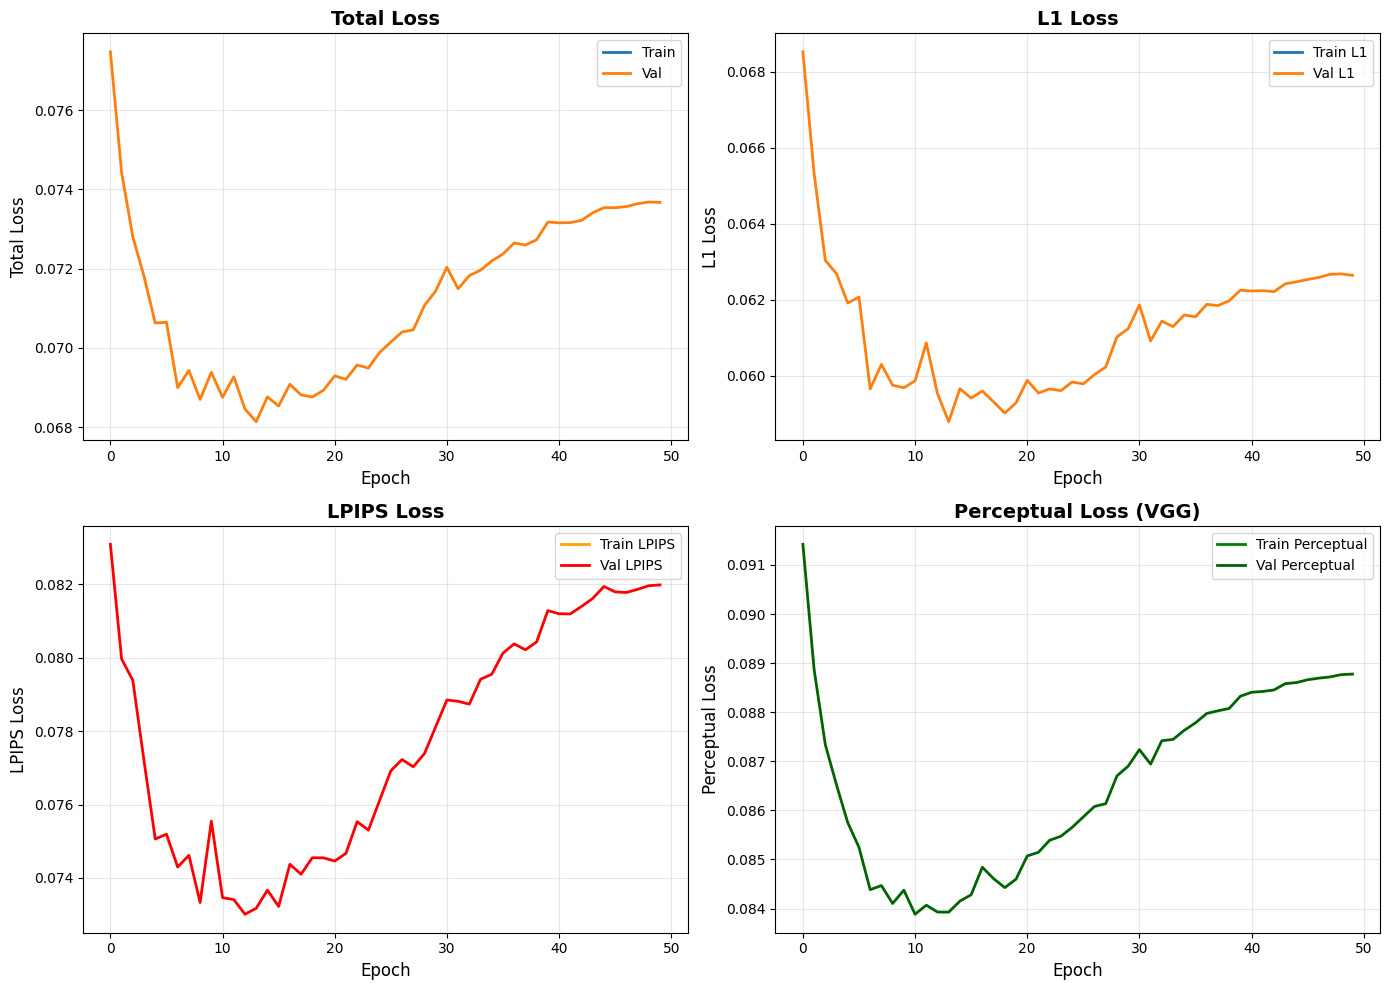


✓ Training curves saved


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Total loss
axes[0, 0].plot(history['train_loss'], label='Train', linewidth=2)
if len(history['val_loss']) > 0:
    val_epochs = np.arange(0, len(history['train_loss']), CFG["val_every"])
    axes[0, 0].plot(val_epochs, history['val_loss'], label='Val', linewidth=2)
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Total Loss', fontsize=12)
axes[0, 0].set_title('Total Loss', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# L1 loss
axes[0, 1].plot(history['train_l1'], label='Train L1', linewidth=2)
if len(history['val_l1']) > 0:
    axes[0, 1].plot(val_epochs, history['val_l1'], label='Val L1', linewidth=2)
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('L1 Loss', fontsize=12)
axes[0, 1].set_title('L1 Loss', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# LPIPS loss
axes[1, 0].plot(history['train_lpips'], label='Train LPIPS', linewidth=2, color='orange')
if len(history['val_lpips']) > 0:
    axes[1, 0].plot(val_epochs, history['val_lpips'], label='Val LPIPS', linewidth=2, color='red')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('LPIPS Loss', fontsize=12)
axes[1, 0].set_title('LPIPS Loss', fontsize=14, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Perceptual loss
axes[1, 1].plot(history['train_perceptual'], label='Train Perceptual', linewidth=2, color='green')
if len(history['val_perceptual']) > 0:
    axes[1, 1].plot(val_epochs, history['val_perceptual'], label='Val Perceptual', linewidth=2, color='darkgreen')
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Perceptual Loss', fontsize=12)
axes[1, 1].set_title('Perceptual Loss (VGG)', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(Path(CFG["save_dir"]) / "training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Training curves saved")


# ## 10. Final Summary



In [14]:

print("\n" + "="*80)
print("TRAINING SUMMARY")
print("="*80)

print(f"\n📊 Final Metrics:")
print(f"  Best validation loss: {best_val_loss:.4f}")
print(f"  Final train loss:     {history['train_loss'][-1]:.4f}")

# ✅ 수정된 부분
if len(history['val_loss']) > 0:
    print(f"  Final val loss:       {history['val_loss'][-1]:.4f}")
else:
    print(f"  Final val loss:       N/A")

print(f"\n📁 Saved Files:")
print(f"  Model checkpoints: {CFG['save_dir']}/checkpoint_epoch_*.pt")
print(f"  Best model:        {CFG['save_dir']}/best_refiner.pt")
print(f"  Training history:  {CFG['save_dir']}/training_history.json")
print(f"  Training curves:   {CFG['save_dir']}/training_curves.png")

print(f"\n💡 Model Architecture:")
print(f"  - Attention-based slice-aware refiner")
print(f"  - Query: Center draft")
print(f"  - Key/Value: High-quality neighbors (Q > Mean + {CFG['quality_threshold_factor']}σ)")
print(f"  - Context window: ±{CFG['context_window']} slices")
print(f"  - Total parameters: {sum(p.numel() for p in model.parameters()):,}")

print(f"\n🎯 Loss Configuration:")
print(f"  - L1:         {CFG['w_l1']:.1f}")
print(f"  - LPIPS:      {CFG['w_lpips']:.1f}")
print(f"  - Perceptual: {CFG['w_perceptual']:.1f}")

print("\n" + "="*80)
print("Training complete! Use best_refiner.pt for inference.")
print("="*80)



TRAINING SUMMARY

📊 Final Metrics:
  Best validation loss: 0.0681
  Final train loss:     nan
  Final val loss:       0.0737

📁 Saved Files:
  Model checkpoints: ./ckpt_attention_refiner/checkpoint_epoch_*.pt
  Best model:        ./ckpt_attention_refiner/best_refiner.pt
  Training history:  ./ckpt_attention_refiner/training_history.json
  Training curves:   ./ckpt_attention_refiner/training_curves.png

💡 Model Architecture:
  - Attention-based slice-aware refiner
  - Query: Center draft
  - Key/Value: High-quality neighbors (Q > Mean + 1.0σ)
  - Context window: ±3 slices
  - Total parameters: 8,279,489

🎯 Loss Configuration:
  - L1:         0.5
  - LPIPS:      0.3
  - Perceptual: 0.2

Training complete! Use best_refiner.pt for inference.


In [15]:
print("\n" + "="*80)
print("Visualizing Refiner Results")
print("="*80)

# Load best refiner
best_checkpoint = torch.load(Path(CFG["save_dir"]) / "best_refiner.pt", map_location=CFG["device"])
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval()

print(f"✓ Best refiner loaded (epoch {best_checkpoint['epoch']}, val_loss: {best_checkpoint['val_loss']:.4f})")


Visualizing Refiner Results
✓ Best refiner loaded (epoch 13, val_loss: 0.0681)


In [16]:
@torch.no_grad()
def compute_quality_and_refine(dataset, model, quality_predictor, device, num_samples=20):
    """
    Compute quality scores and refine samples
    """
    results = []
    
    # Random sample indices
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)
    
    for idx in tqdm(indices, desc="Processing samples"):
        batch = dataset[idx]
        
        # Move to device
        center_draft = batch['center_draft'].unsqueeze(0).to(device)
        neighbors = batch['neighbors'].unsqueeze(0).to(device)
        center_ct = batch['center_ct'].unsqueeze(0).to(device)
        center_gt = batch['center_gt'].unsqueeze(0).to(device)
        neighbor_qualities = batch['neighbor_qualities'].unsqueeze(0).to(device)
        
        # Compute draft quality
        draft_quality = quality_predictor(center_draft)
        
        # Refine
        refined, attn_weights = model(center_draft, neighbors, center_ct, neighbor_qualities)
        
        # Compute refined quality
        refined_quality = quality_predictor(refined)
        
        # Convert to numpy
        center_draft_np = (center_draft.squeeze().cpu().numpy() + 1) / 2
        center_ct_np = (center_ct.squeeze().cpu().numpy() + 1) / 2
        center_gt_np = (center_gt.squeeze().cpu().numpy() + 1) / 2
        refined_np = (refined.squeeze().cpu().numpy() + 1) / 2
        
        results.append({
            'patient': batch['patient'],
            'slice_name': batch['slice_name'],
            'draft': center_draft_np,
            'ct': center_ct_np,
            'gt': center_gt_np,
            'refined': refined_np,
            'draft_quality': draft_quality.item(),
            'refined_quality': refined_quality.item(),
            'neighbor_qualities': neighbor_qualities.squeeze().cpu().numpy(),
        })
    
    return results


# Compute on validation set
val_results = compute_quality_and_refine(
    val_dataset,
    model,
    quality_predictor,
    CFG["device"],
    num_samples=50
)

print(f"\n✓ Processed {len(val_results)} samples")

Processing samples: 100%|██████████| 50/50 [00:04<00:00, 11.48it/s]


✓ Processed 50 samples


In [17]:
# Compute on validation set
val_results = compute_quality_and_refine(
    val_dataset,
    model,
    quality_predictor,
    CFG["device"],
    num_samples=50
)

print(f"\n✓ Processed {len(val_results)} samples")


Processing samples: 100%|██████████| 50/50 [00:04<00:00, 11.58it/s]


✓ Processed 50 samples


In [18]:
# Sort by draft quality
val_results_sorted = sorted(val_results, key=lambda x: x['draft_quality'])

# Get HIGH, MEDIUM, LOW quality samples
n_show = 5

# LOW quality (bottom 5)
low_quality_samples = val_results_sorted[:n_show]

# MEDIUM quality (middle 5)
mid_idx = len(val_results_sorted) // 2
medium_quality_samples = val_results_sorted[mid_idx:mid_idx+n_show]

# HIGH quality (top 5)
high_quality_samples = val_results_sorted[-n_show:]

print("\n" + "="*80)
print("Sample Selection")
print("="*80)

print(f"\nLOW Quality (Bottom {n_show}):")
for i, sample in enumerate(low_quality_samples, 1):
    print(f"  {i}. {sample['patient']:20s} / {sample['slice_name']:25s}")
    print(f"     Draft Q: {sample['draft_quality']:.4f} → Refined Q: {sample['refined_quality']:.4f} "
          f"(Δ: {sample['refined_quality']-sample['draft_quality']:+.4f})")

print(f"\nMEDIUM Quality (Middle {n_show}):")
for i, sample in enumerate(medium_quality_samples, 1):
    print(f"  {i}. {sample['patient']:20s} / {sample['slice_name']:25s}")
    print(f"     Draft Q: {sample['draft_quality']:.4f} → Refined Q: {sample['refined_quality']:.4f} "
          f"(Δ: {sample['refined_quality']-sample['draft_quality']:+.4f})")

print(f"\nHIGH Quality (Top {n_show}):")
for i, sample in enumerate(high_quality_samples, 1):
    print(f"  {i}. {sample['patient']:20s} / {sample['slice_name']:25s}")
    print(f"     Draft Q: {sample['draft_quality']:.4f} → Refined Q: {sample['refined_quality']:.4f} "
          f"(Δ: {sample['refined_quality']-sample['draft_quality']:+.4f})")

print("="*80)


Sample Selection

LOW Quality (Bottom 5):
  1. CNUH_X_185           / 0020                     
     Draft Q: 0.1302 → Refined Q: 0.8995 (Δ: +0.7693)
  2. CNUH_X_202           / 0014                     
     Draft Q: 0.1418 → Refined Q: 0.8765 (Δ: +0.7347)
  3. CNUH_X_184           / 0010                     
     Draft Q: 0.1474 → Refined Q: 0.9080 (Δ: +0.7606)
  4. CNUH_X_203           / 0011                     
     Draft Q: 0.1893 → Refined Q: 0.9040 (Δ: +0.7147)
  5. CNUH_X_182           / 0020                     
     Draft Q: 0.1969 → Refined Q: 0.8577 (Δ: +0.6608)

MEDIUM Quality (Middle 5):
  1. CNUH_X_201           / 0017                     
     Draft Q: 0.5285 → Refined Q: 0.8619 (Δ: +0.3335)
  2. CNUH_X_189           / 0015                     
     Draft Q: 0.5758 → Refined Q: 0.8744 (Δ: +0.2987)
  3. CNUH_X_182           / 0019                     
     Draft Q: 0.6271 → Refined Q: 0.8279 (Δ: +0.2009)
  4. CNUH_X_186           / 0010                     
     Draft 

In [19]:
def visualize_refinement_results(samples, title, save_path):
    """
    Visualize CT → Draft → Refined → GT
    With quality scores
    """
    n_samples = len(samples)
    fig, axes = plt.subplots(4, n_samples, figsize=(4*n_samples, 16))
    
    if n_samples == 1:
        axes = axes.reshape(4, 1)
    
    for i, sample in enumerate(samples):
        # CT
        axes[0, i].imshow(sample['ct'], cmap='gray', vmin=0, vmax=1)
        axes[0, i].set_title(
            f"CT Input\n{sample['patient']}\n{sample['slice_name'][:20]}",
            fontsize=10
        )
        axes[0, i].axis('off')
        
        # Draft
        axes[1, i].imshow(sample['draft'], cmap='gray', vmin=0, vmax=1)
        quality_color = 'red' if sample['draft_quality'] < 0.5 else 'orange' if sample['draft_quality'] < 0.7 else 'green'
        axes[1, i].set_title(
            f"Draft (Stage 1)\nQuality: {sample['draft_quality']:.4f}",
            fontsize=10,
            color=quality_color,
            fontweight='bold'
        )
        axes[1, i].axis('off')
        
        # Refined
        axes[2, i].imshow(sample['refined'], cmap='gray', vmin=0, vmax=1)
        delta = sample['refined_quality'] - sample['draft_quality']
        delta_color = 'green' if delta > 0 else 'red'
        axes[2, i].set_title(
            f"Refined (Stage 2)\nQuality: {sample['refined_quality']:.4f}\n(Δ: {delta:+.4f})",
            fontsize=10,
            color=delta_color,
            fontweight='bold'
        )
        axes[2, i].axis('off')
        
        # GT
        axes[3, i].imshow(sample['gt'], cmap='gray', vmin=0, vmax=1)
        axes[3, i].set_title("GT MRI", fontsize=10)
        axes[3, i].axis('off')
    
    # Row labels
    fig.text(0.02, 0.875, 'CT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
    fig.text(0.02, 0.625, 'Draft', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
    fig.text(0.02, 0.375, 'Refined', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
    fig.text(0.02, 0.125, 'GT', fontsize=14, fontweight='bold', ha='center', va='center', rotation=90)
    
    plt.suptitle(title, fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0.03, 0, 1, 0.96])
    
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")


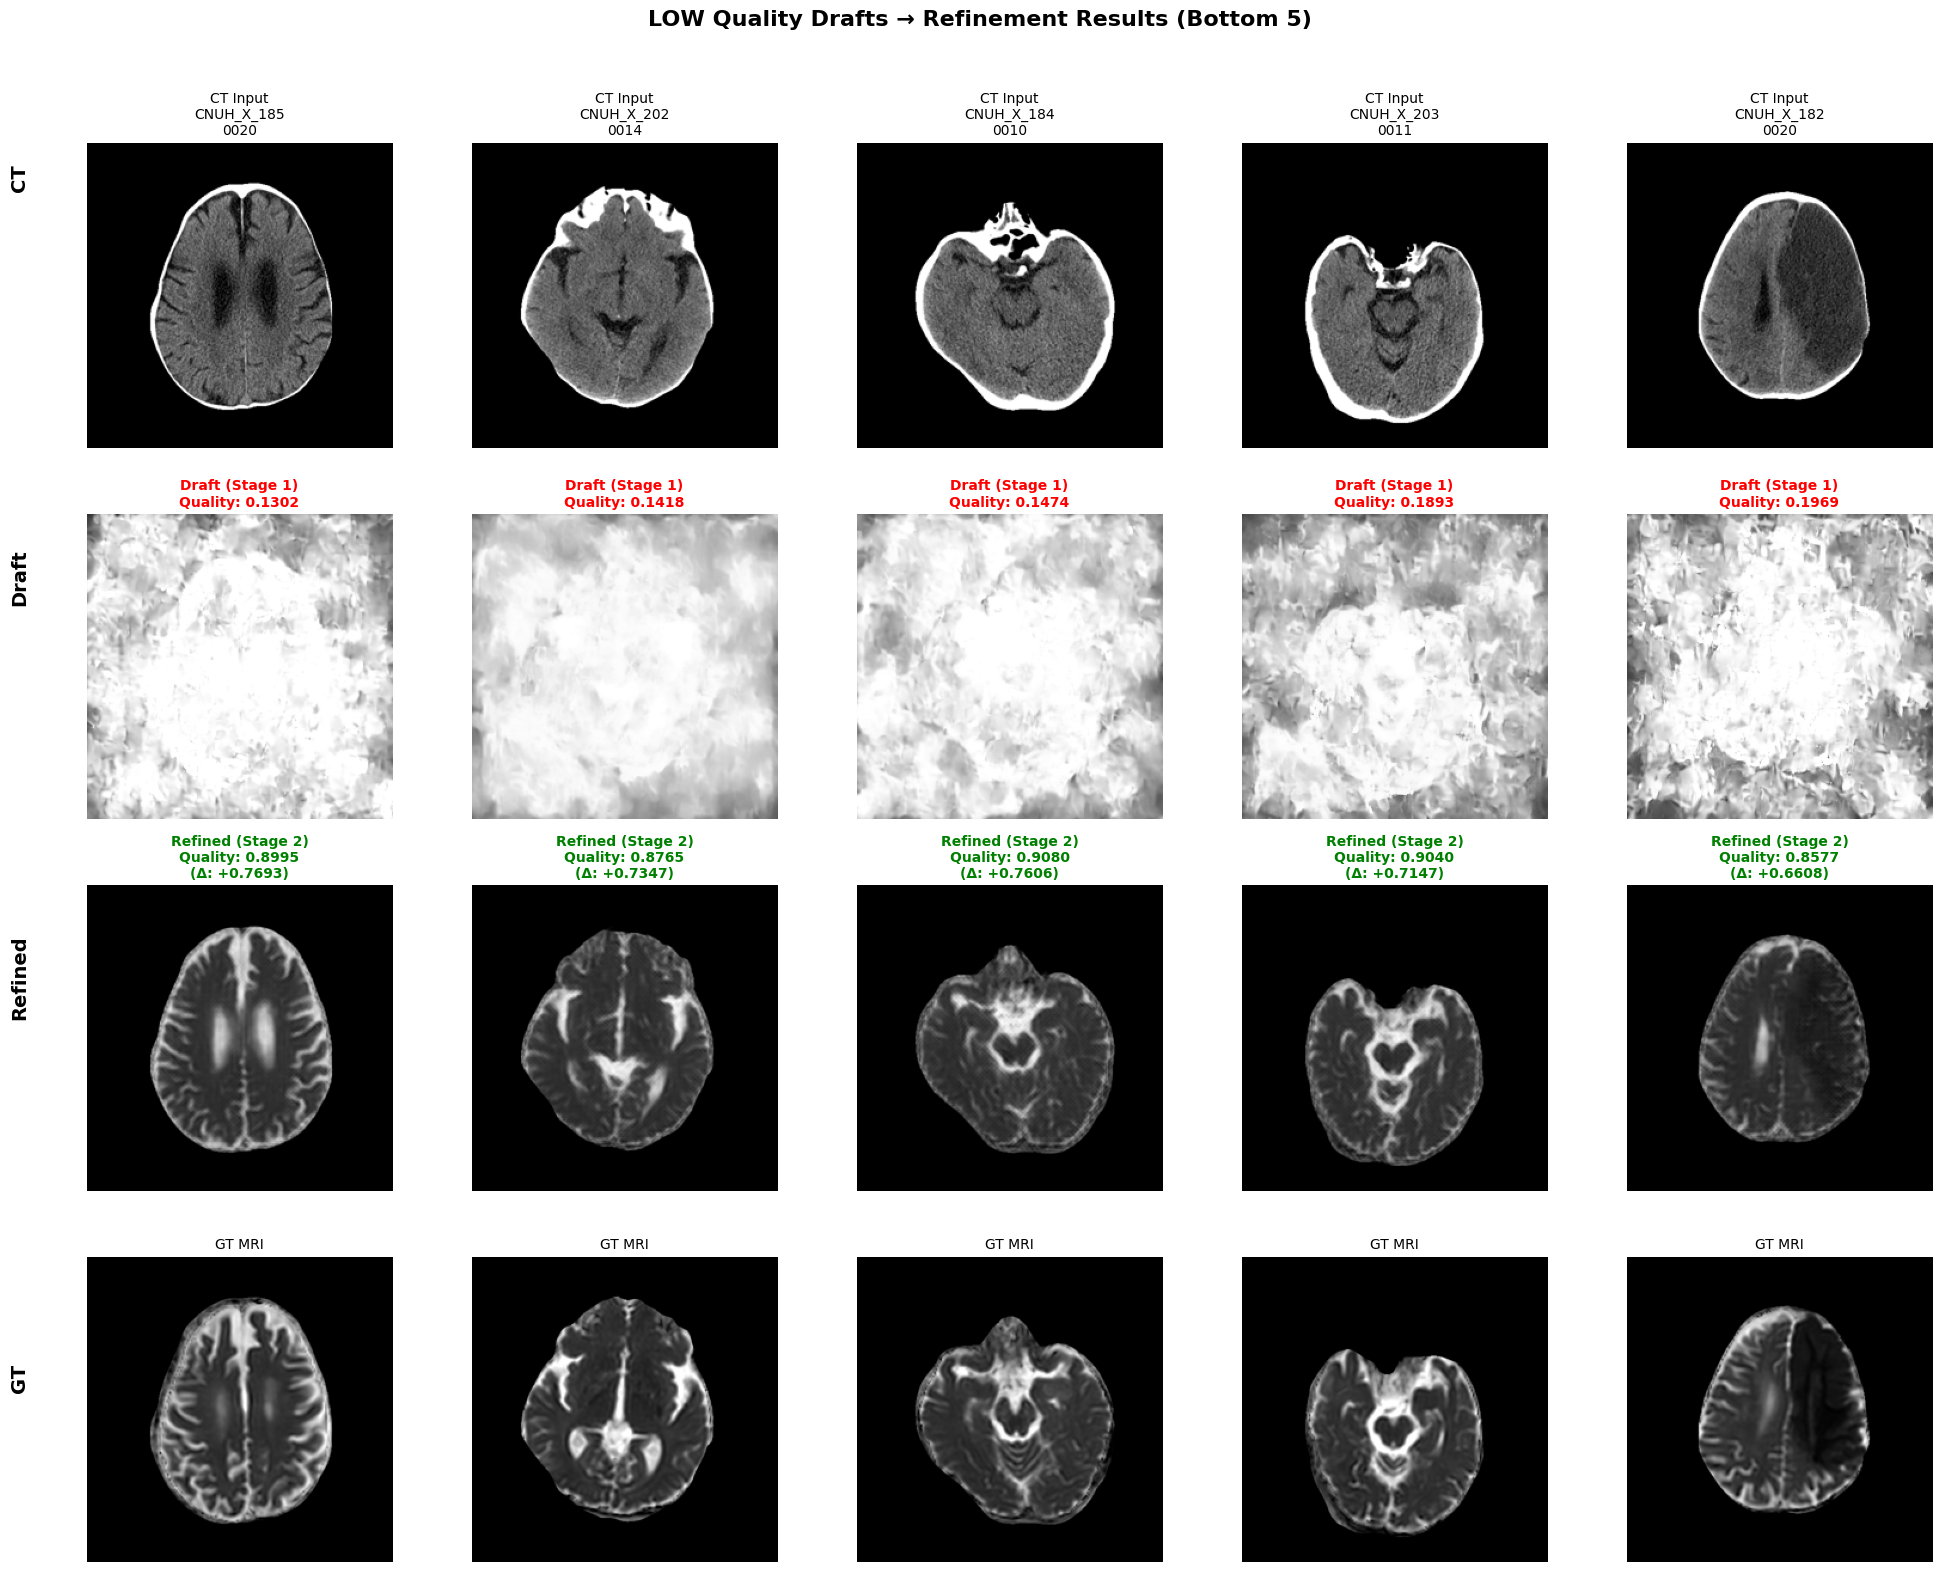

✓ Saved: ckpt_attention_refiner/results_low_quality.png


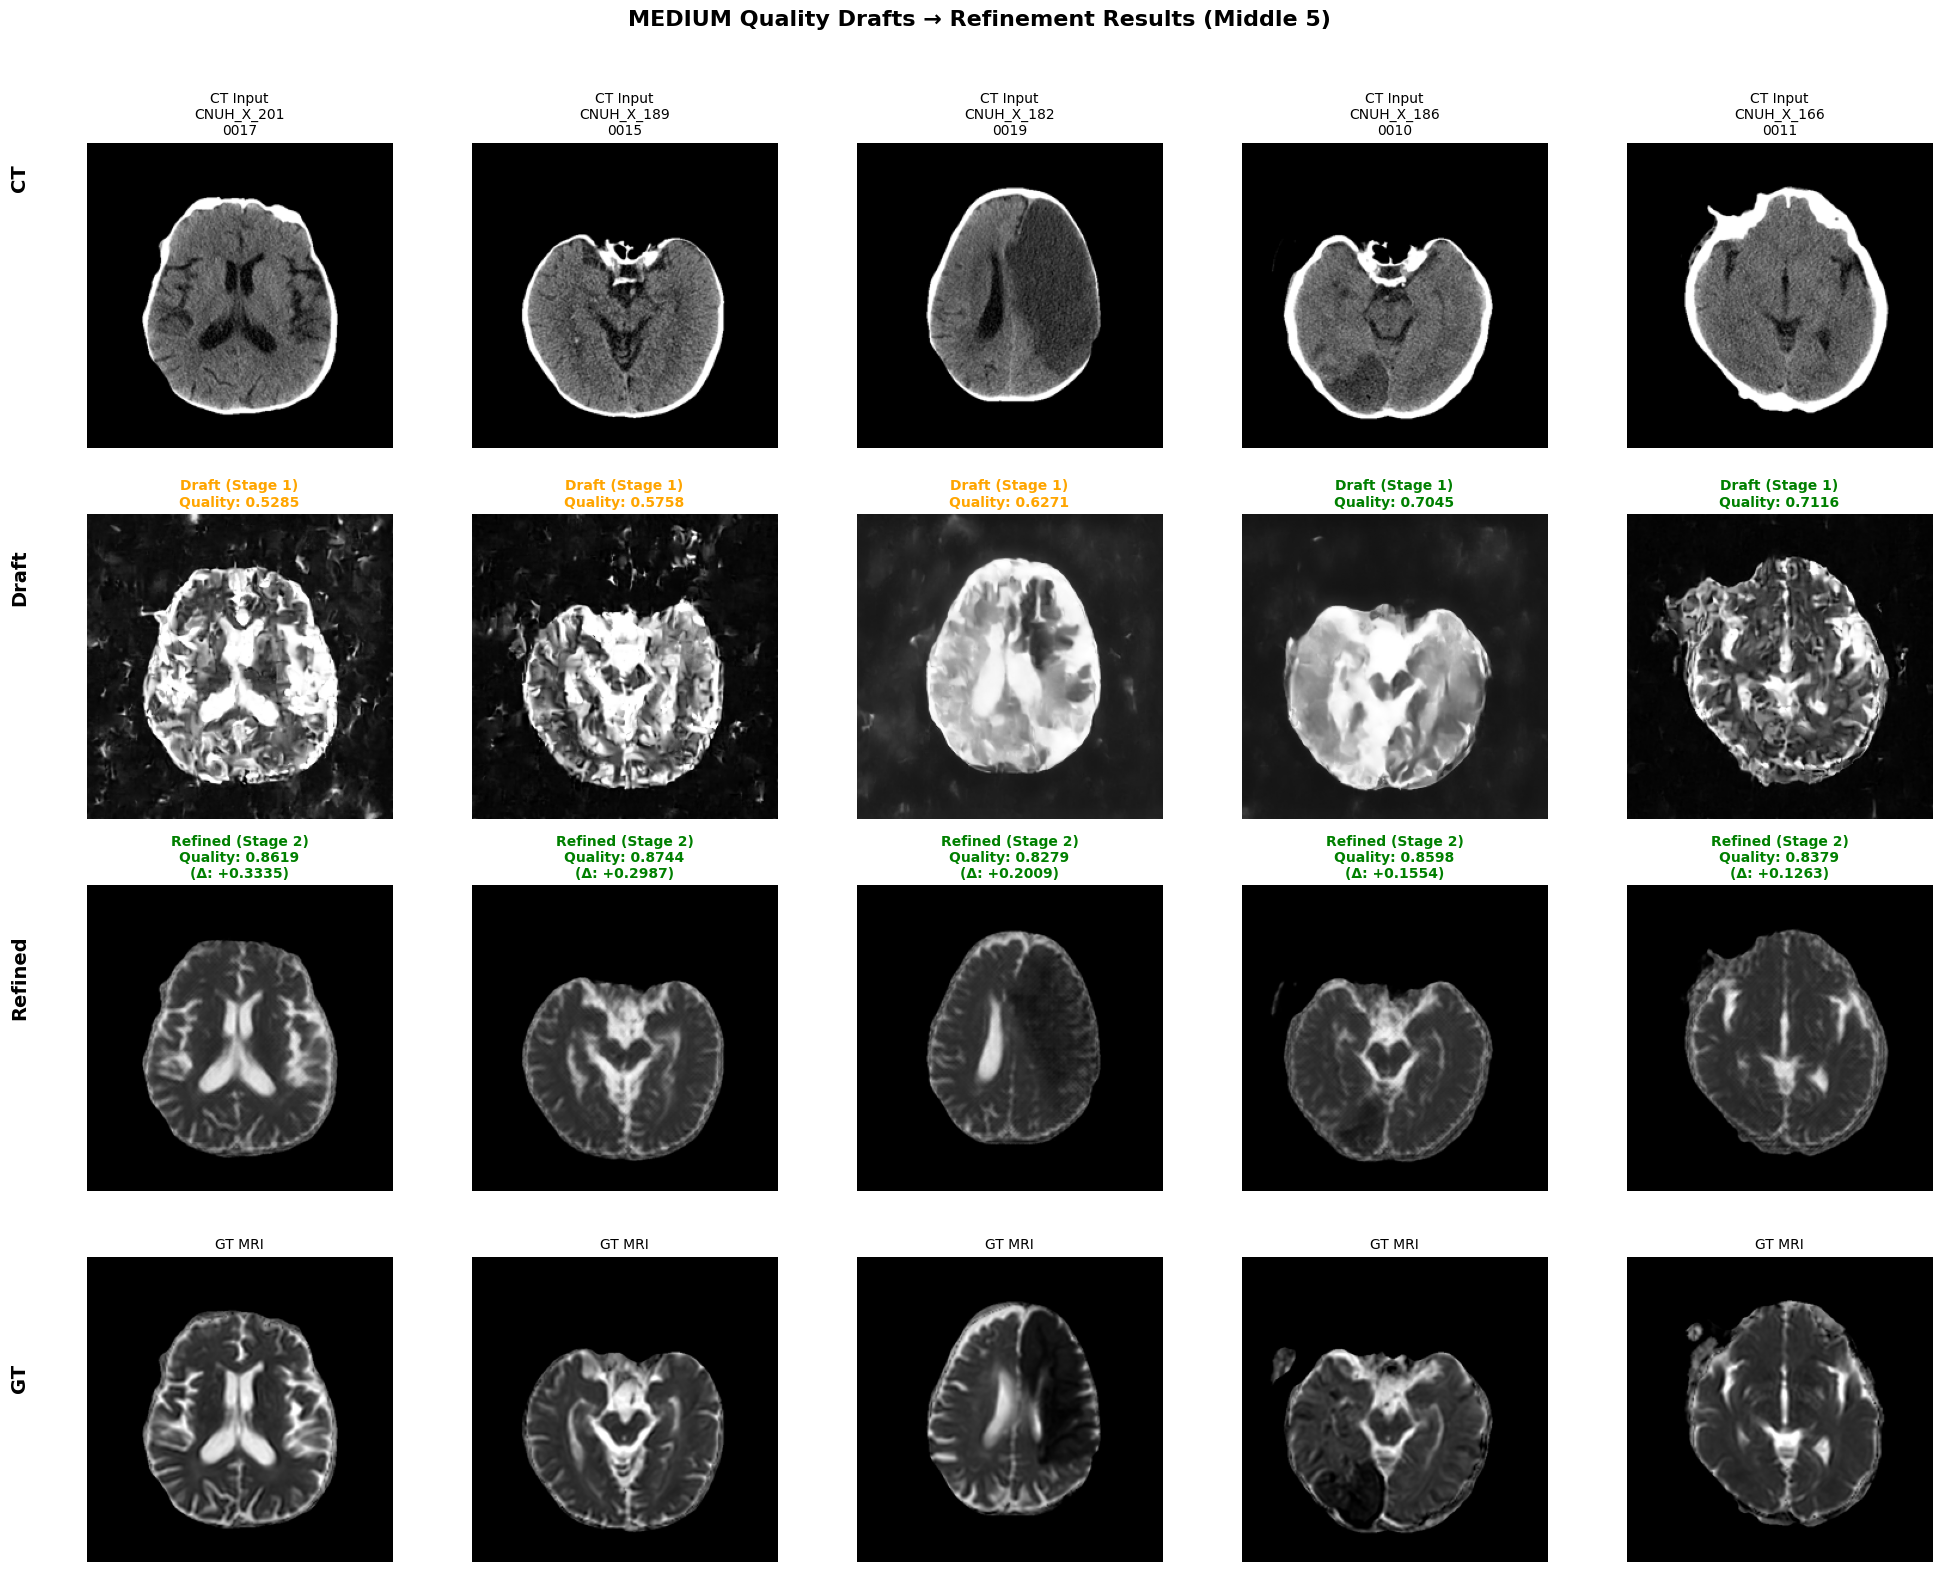

✓ Saved: ckpt_attention_refiner/results_medium_quality.png


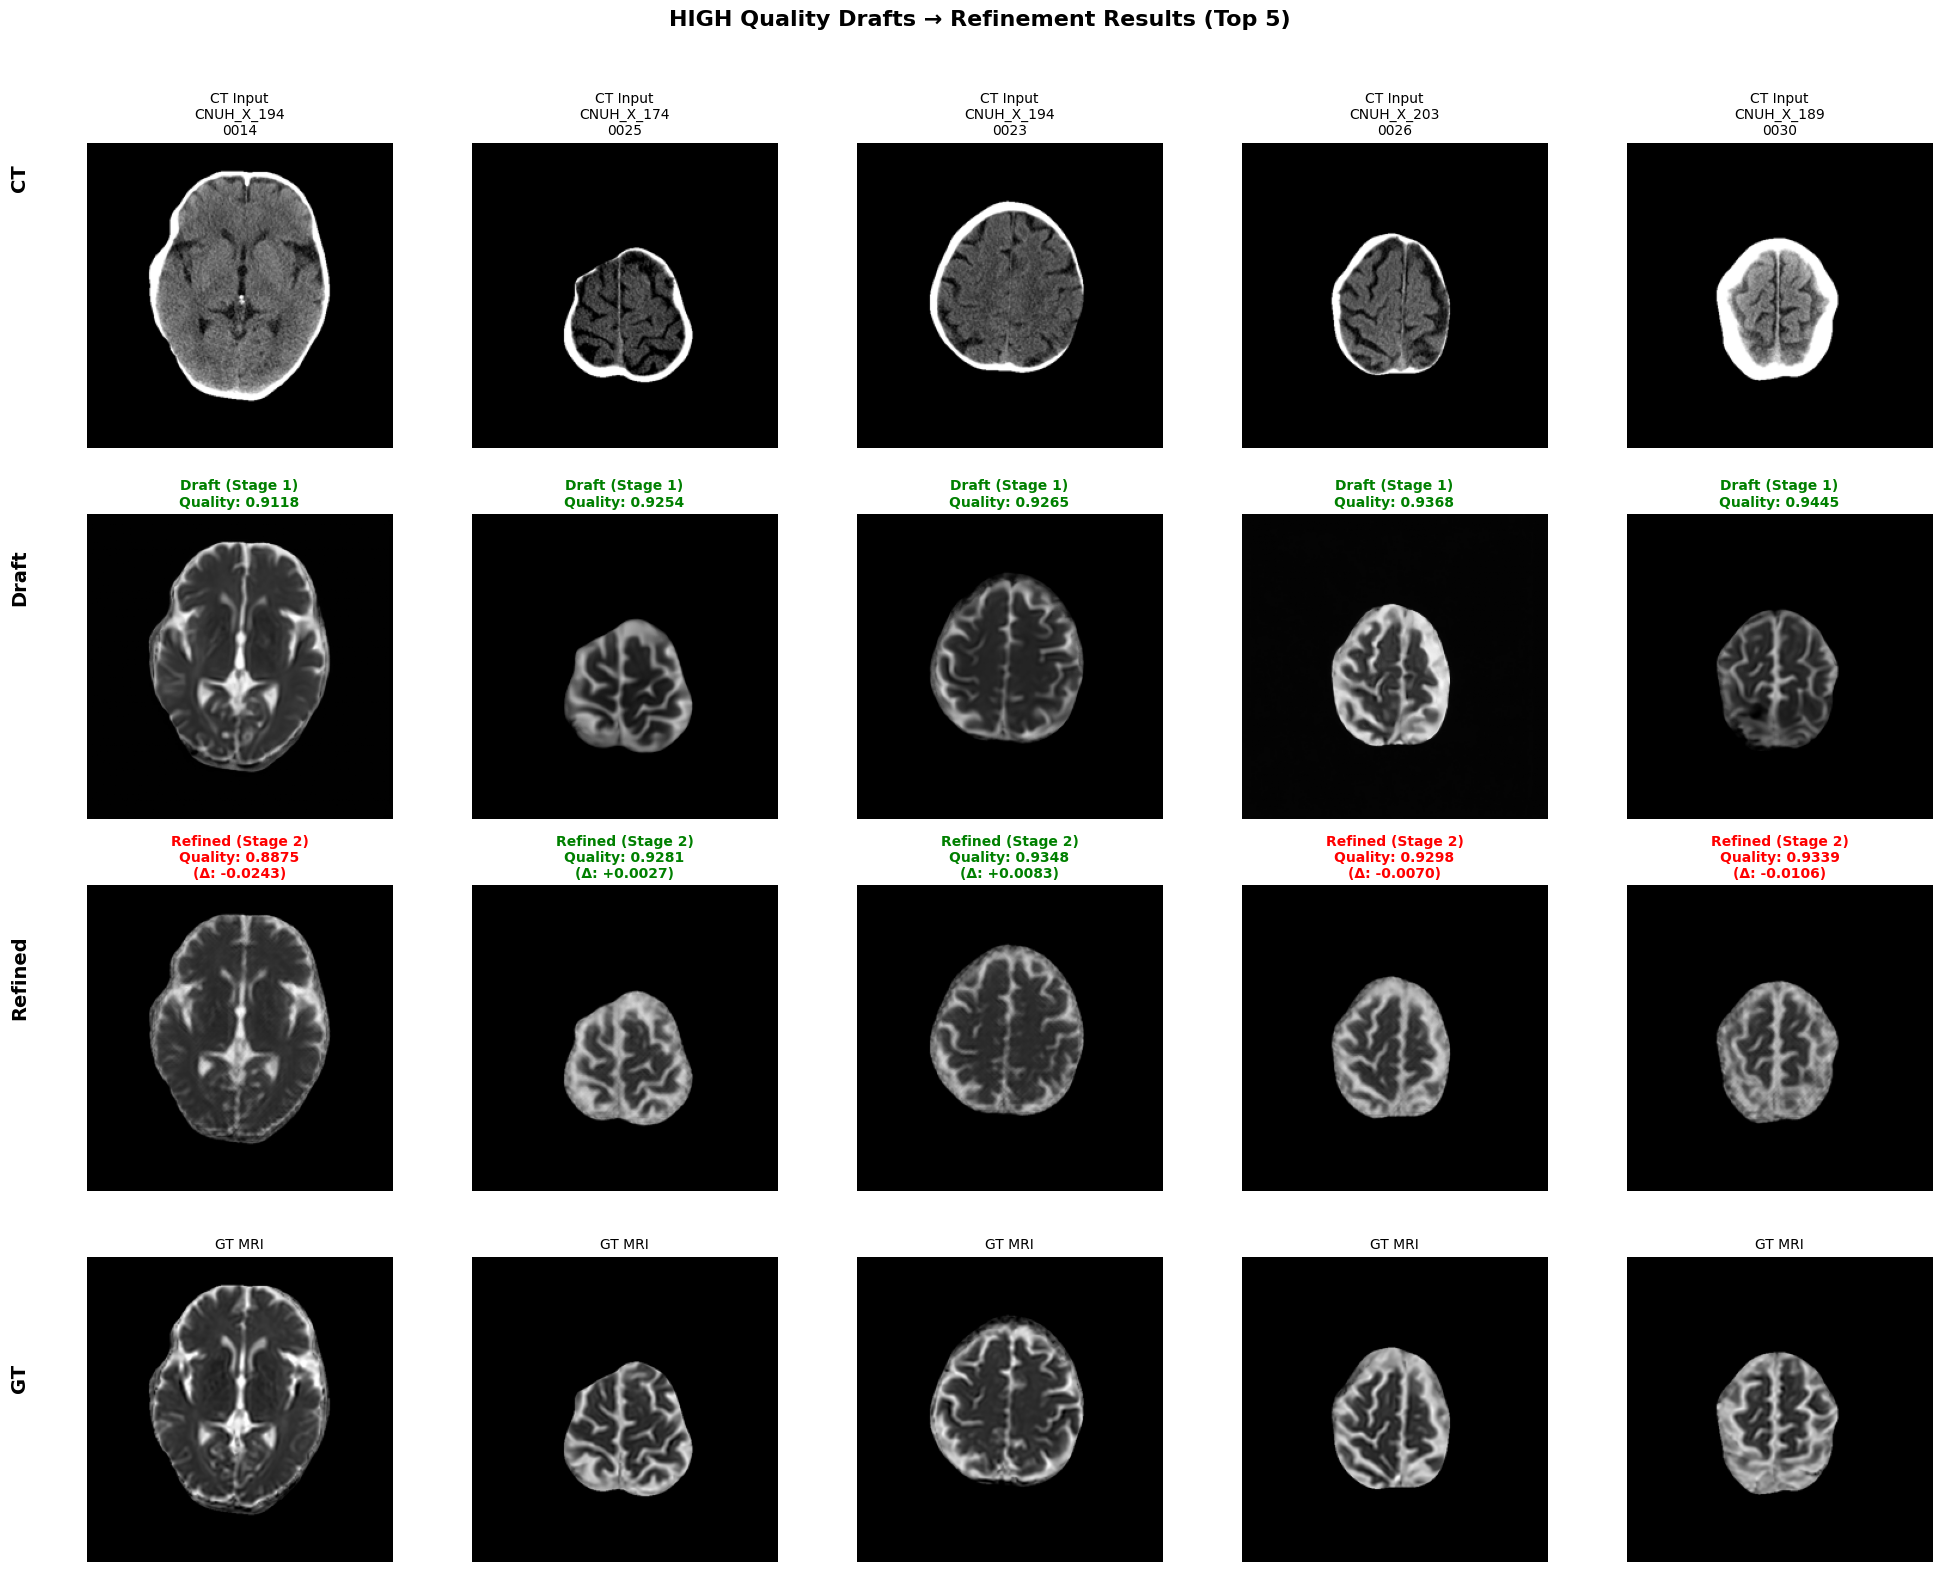

✓ Saved: ckpt_attention_refiner/results_high_quality.png


In [20]:
# Visualize LOW quality
visualize_refinement_results(
    low_quality_samples,
    f"LOW Quality Drafts → Refinement Results (Bottom {n_show})",
    Path(CFG["save_dir"]) / "results_low_quality.png"
)

# Visualize MEDIUM quality
visualize_refinement_results(
    medium_quality_samples,
    f"MEDIUM Quality Drafts → Refinement Results (Middle {n_show})",
    Path(CFG["save_dir"]) / "results_medium_quality.png"
)

# Visualize HIGH quality
visualize_refinement_results(
    high_quality_samples,
    f"HIGH Quality Drafts → Refinement Results (Top {n_show})",
    Path(CFG["save_dir"]) / "results_high_quality.png"
)


In [21]:
def visualize_detailed_comparison(sample, save_path):
    """
    Detailed single sample visualization with difference maps
    """
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    
    # Row 1: Images
    axes[0, 0].imshow(sample['ct'], cmap='gray', vmin=0, vmax=1)
    axes[0, 0].set_title("CT Input", fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(sample['draft'], cmap='gray', vmin=0, vmax=1)
    axes[0, 1].set_title(
        f"Draft\nQ: {sample['draft_quality']:.4f}",
        fontsize=12, fontweight='bold'
    )
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(sample['refined'], cmap='gray', vmin=0, vmax=1)
    delta = sample['refined_quality'] - sample['draft_quality']
    axes[0, 2].set_title(
        f"Refined\nQ: {sample['refined_quality']:.4f} ({delta:+.4f})",
        fontsize=12, fontweight='bold', color='green' if delta > 0 else 'red'
    )
    axes[0, 2].axis('off')
    
    axes[0, 3].imshow(sample['gt'], cmap='gray', vmin=0, vmax=1)
    axes[0, 3].set_title("GT MRI", fontsize=12, fontweight='bold')
    axes[0, 3].axis('off')
    
    # Neighbor qualities
    neighbor_q = sample['neighbor_qualities']
    valid_neighbors = neighbor_q[neighbor_q > 0]
    axes[0, 4].barh(range(len(valid_neighbors)), valid_neighbors, color='skyblue', edgecolor='black')
    axes[0, 4].set_xlabel('Quality Score', fontsize=11)
    axes[0, 4].set_ylabel('Neighbor Index', fontsize=11)
    axes[0, 4].set_title(f'Neighbor Qualities\n(n={len(valid_neighbors)})', fontsize=12, fontweight='bold')
    axes[0, 4].set_xlim(0, 1)
    axes[0, 4].grid(alpha=0.3, axis='x')
    
    # Row 2: Difference maps
    # Draft - GT
    diff_draft = sample['draft'] - sample['gt']
    im1 = axes[1, 0].imshow(diff_draft, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
    axes[1, 0].set_title(f"Draft - GT\nMAE: {np.abs(diff_draft).mean():.4f}", fontsize=11)
    axes[1, 0].axis('off')
    plt.colorbar(im1, ax=axes[1, 0], fraction=0.046, pad=0.04)
    
    # Refined - GT
    diff_refined = sample['refined'] - sample['gt']
    im2 = axes[1, 1].imshow(diff_refined, cmap='RdBu_r', vmin=-0.3, vmax=0.3)
    axes[1, 1].set_title(f"Refined - GT\nMAE: {np.abs(diff_refined).mean():.4f}", fontsize=11)
    axes[1, 1].axis('off')
    plt.colorbar(im2, ax=axes[1, 1], fraction=0.046, pad=0.04)
    
    # Improvement (Draft-GT) - (Refined-GT)
    improvement = np.abs(diff_draft) - np.abs(diff_refined)
    im3 = axes[1, 2].imshow(improvement, cmap='RdYlGn', vmin=-0.2, vmax=0.2)
    axes[1, 2].set_title(
        f"Improvement Map\nMean: {improvement.mean():.4f}",
        fontsize=11,
        color='green' if improvement.mean() > 0 else 'red'
    )
    axes[1, 2].axis('off')
    plt.colorbar(im3, ax=axes[1, 2], fraction=0.046, pad=0.04)
    
    # Absolute error: Draft
    abs_draft = np.abs(diff_draft)
    im4 = axes[1, 3].imshow(abs_draft, cmap='hot', vmin=0, vmax=0.3)
    axes[1, 3].set_title(f"Abs Error (Draft)\nMean: {abs_draft.mean():.4f}", fontsize=11)
    axes[1, 3].axis('off')
    plt.colorbar(im4, ax=axes[1, 3], fraction=0.046, pad=0.04)
    
    # Absolute error: Refined
    abs_refined = np.abs(diff_refined)
    im5 = axes[1, 4].imshow(abs_refined, cmap='hot', vmin=0, vmax=0.3)
    axes[1, 4].set_title(f"Abs Error (Refined)\nMean: {abs_refined.mean():.4f}", fontsize=11)
    axes[1, 4].axis('off')
    plt.colorbar(im5, ax=axes[1, 4], fraction=0.046, pad=0.04)
    
    plt.suptitle(
        f"{sample['patient']} / {sample['slice_name']}\n"
        f"Draft Q: {sample['draft_quality']:.4f} → Refined Q: {sample['refined_quality']:.4f}",
        fontsize=14, fontweight='bold', y=0.98
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Saved: {save_path}")


Generating Detailed Visualizations

Best improvement:
  CNUH_X_185 / 0020
  0.1302 → 0.8995 (+0.7693)


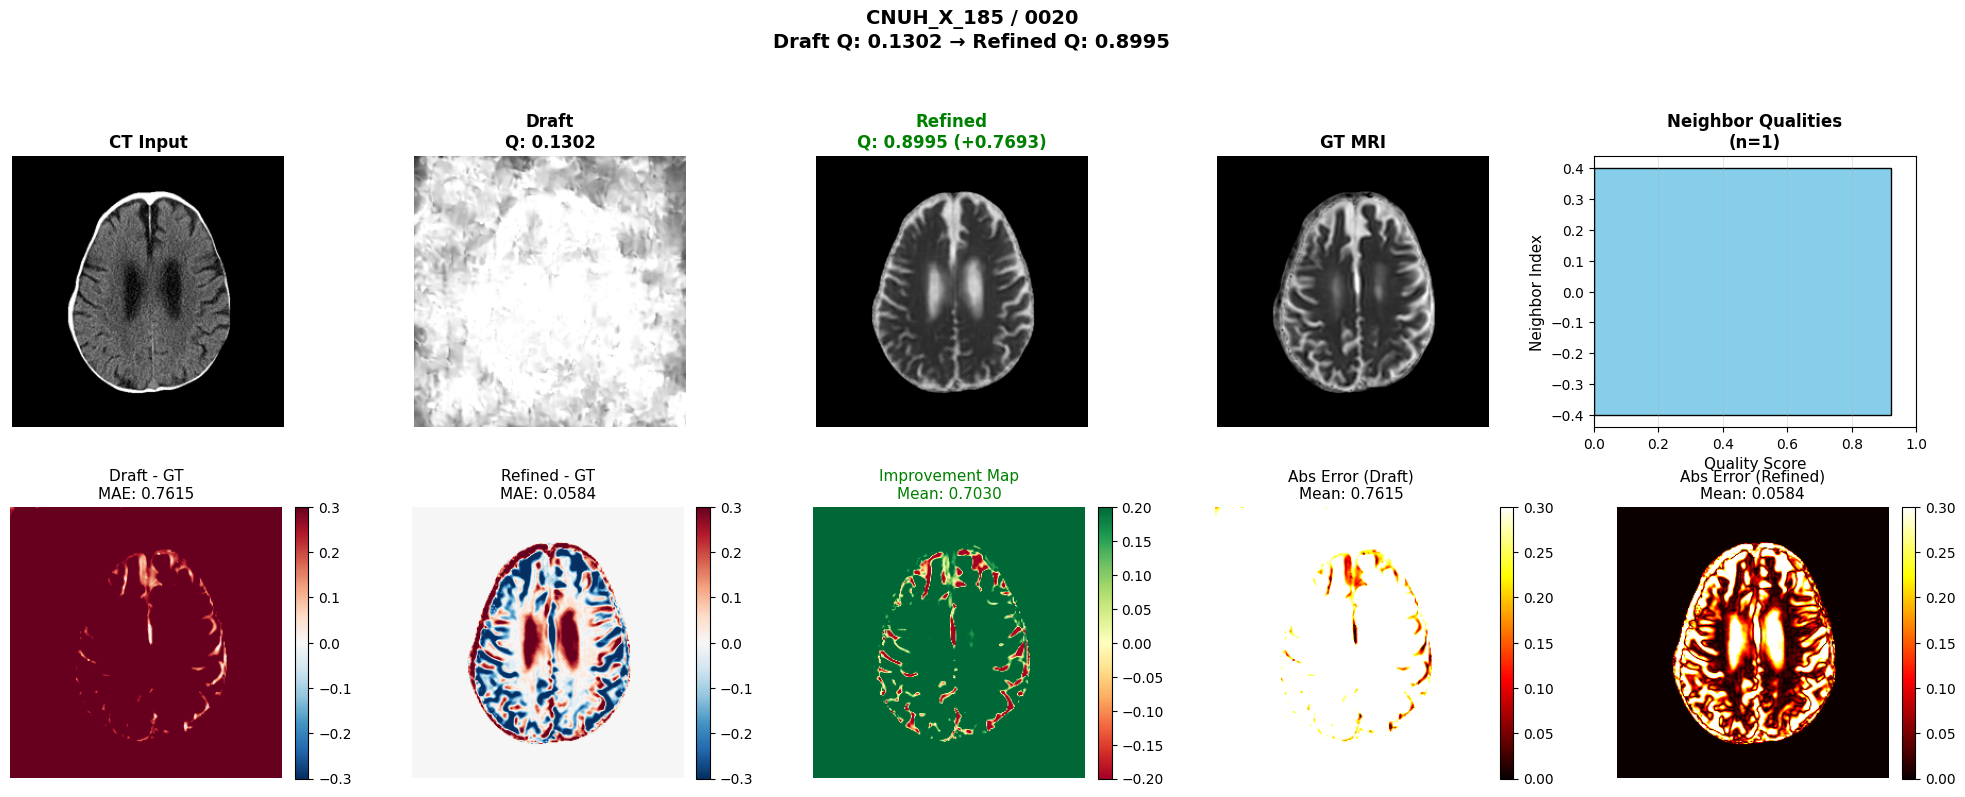

✓ Saved: ckpt_attention_refiner/detailed_best_improvement.png

Worst case:
  CNUH_X_194 / 0014
  0.9118 → 0.8875 (-0.0243)


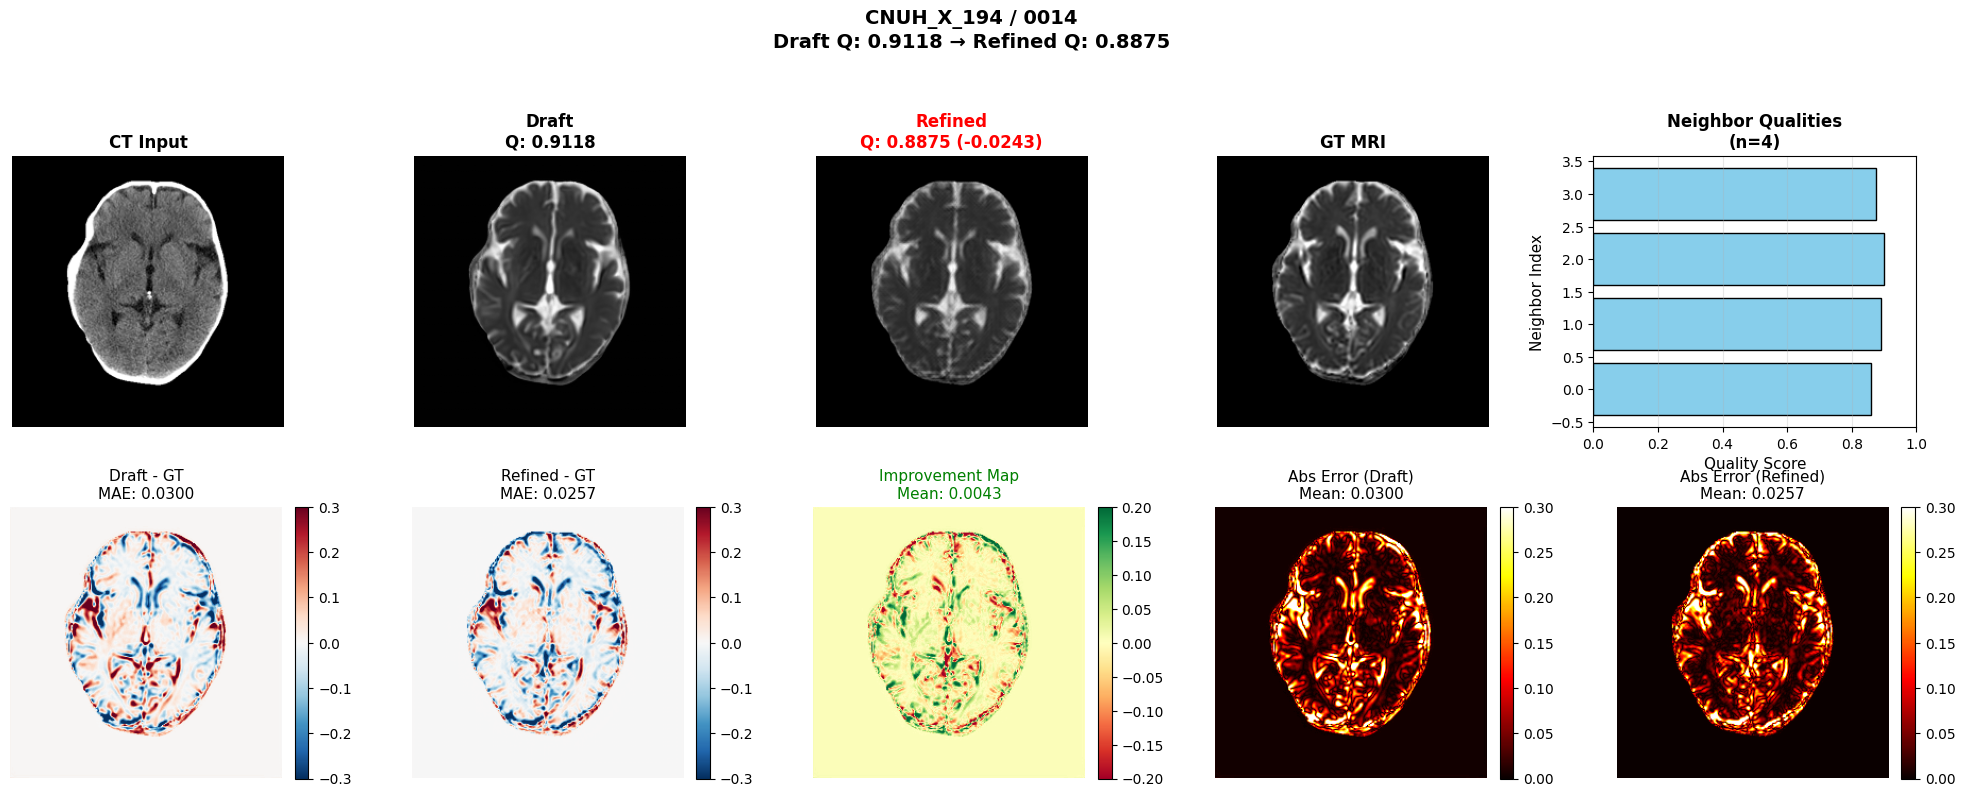

✓ Saved: ckpt_attention_refiner/detailed_worst_case.png


In [22]:
# Detailed visualization for best improvement
improvements = [(s['refined_quality'] - s['draft_quality'], s) for s in val_results]
improvements.sort(reverse=True, key=lambda x: x[0])

print("\n" + "="*80)
print("Generating Detailed Visualizations")
print("="*80)

# Best improvement
best_improvement = improvements[0][1]
print(f"\nBest improvement:")
print(f"  {best_improvement['patient']} / {best_improvement['slice_name']}")
print(f"  {best_improvement['draft_quality']:.4f} → {best_improvement['refined_quality']:.4f} "
      f"(+{improvements[0][0]:.4f})")

visualize_detailed_comparison(
    best_improvement,
    Path(CFG["save_dir"]) / "detailed_best_improvement.png"
)

# Worst case (if quality decreased)
worst_improvement = improvements[-1][1]
print(f"\nWorst case:")
print(f"  {worst_improvement['patient']} / {worst_improvement['slice_name']}")
print(f"  {worst_improvement['draft_quality']:.4f} → {worst_improvement['refined_quality']:.4f} "
      f"({improvements[-1][0]:+.4f})")

visualize_detailed_comparison(
    worst_improvement,
    Path(CFG["save_dir"]) / "detailed_worst_case.png"
)

In [23]:
# Statistics
print("\n" + "="*80)
print("Refinement Statistics")
print("="*80)

draft_qualities = np.array([s['draft_quality'] for s in val_results])
refined_qualities = np.array([s['refined_quality'] for s in val_results])
improvements_arr = refined_qualities - draft_qualities

print(f"\n📊 Quality Scores:")
print(f"  Draft quality:")
print(f"    Mean: {draft_qualities.mean():.4f}")
print(f"    Std:  {draft_qualities.std():.4f}")
print(f"    Min:  {draft_qualities.min():.4f}")
print(f"    Max:  {draft_qualities.max():.4f}")

print(f"\n  Refined quality:")
print(f"    Mean: {refined_qualities.mean():.4f}")
print(f"    Std:  {refined_qualities.std():.4f}")
print(f"    Min:  {refined_qualities.min():.4f}")
print(f"    Max:  {refined_qualities.max():.4f}")

print(f"\n📈 Improvement:")
print(f"    Mean: {improvements_arr.mean():.4f}")
print(f"    Std:  {improvements_arr.std():.4f}")
print(f"    Min:  {improvements_arr.min():.4f}")
print(f"    Max:  {improvements_arr.max():.4f}")

improved = (improvements_arr > 0).sum()
degraded = (improvements_arr < 0).sum()
unchanged = (improvements_arr == 0).sum()

print(f"\n  Improved:  {improved}/{len(val_results)} ({improved/len(val_results)*100:.1f}%)")
print(f"  Degraded:  {degraded}/{len(val_results)} ({degraded/len(val_results)*100:.1f}%)")
print(f"  Unchanged: {unchanged}/{len(val_results)} ({unchanged/len(val_results)*100:.1f}%)")

print("="*80)


Refinement Statistics

📊 Quality Scores:
  Draft quality:
    Mean: 0.5649
    Std:  0.2733
    Min:  0.1302
    Max:  0.9445

  Refined quality:
    Mean: 0.8910
    Std:  0.0307
    Min:  0.8279
    Max:  0.9498

📈 Improvement:
    Mean: 0.3262
    Std:  0.2719
    Min:  -0.0243
    Max:  0.7693

  Improved:  44/50 (88.0%)
  Degraded:  6/50 (12.0%)
  Unchanged: 0/50 (0.0%)


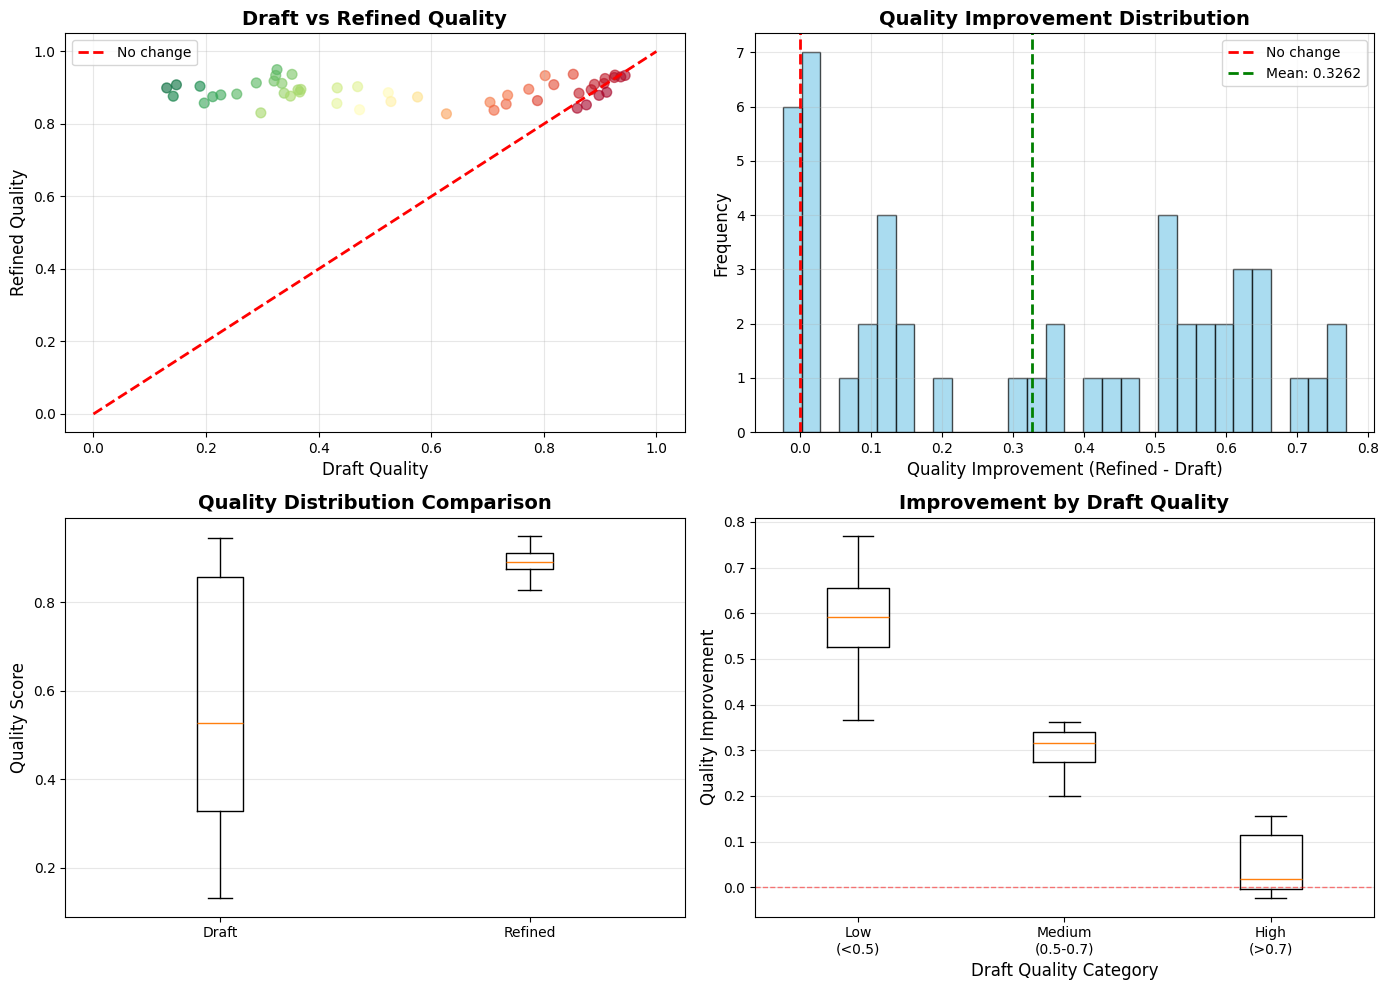


✓ All visualizations saved!


In [24]:
# Quality improvement histogram
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Scatter: Draft vs Refined quality
axes[0, 0].scatter(draft_qualities, refined_qualities, alpha=0.6, s=50, c=improvements_arr, cmap='RdYlGn')
axes[0, 0].plot([0, 1], [0, 1], 'r--', linewidth=2, label='No change')
axes[0, 0].set_xlabel('Draft Quality', fontsize=12)
axes[0, 0].set_ylabel('Refined Quality', fontsize=12)
axes[0, 0].set_title('Draft vs Refined Quality', fontsize=14, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Histogram: Quality improvement
axes[0, 1].hist(improvements_arr, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2, label='No change')
axes[0, 1].axvline(improvements_arr.mean(), color='green', linestyle='--', linewidth=2, 
                   label=f'Mean: {improvements_arr.mean():.4f}')
axes[0, 1].set_xlabel('Quality Improvement (Refined - Draft)', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].set_title('Quality Improvement Distribution', fontsize=14, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot
axes[1, 0].boxplot([draft_qualities, refined_qualities], labels=['Draft', 'Refined'])
axes[1, 0].set_ylabel('Quality Score', fontsize=12)
axes[1, 0].set_title('Quality Distribution Comparison', fontsize=14, fontweight='bold')
axes[1, 0].grid(alpha=0.3, axis='y')

# Improvement by draft quality
# Bin by draft quality
bins = [0, 0.5, 0.7, 1.0]
bin_labels = ['Low\n(<0.5)', 'Medium\n(0.5-0.7)', 'High\n(>0.7)']
binned_improvements = []

for i in range(len(bins)-1):
    mask = (draft_qualities >= bins[i]) & (draft_qualities < bins[i+1])
    if mask.sum() > 0:
        binned_improvements.append(improvements_arr[mask])
    else:
        binned_improvements.append([])

axes[1, 1].boxplot(binned_improvements, labels=bin_labels)
axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.5)
axes[1, 1].set_xlabel('Draft Quality Category', fontsize=12)
axes[1, 1].set_ylabel('Quality Improvement', fontsize=12)
axes[1, 1].set_title('Improvement by Draft Quality', fontsize=14, fontweight='bold')
axes[1, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(Path(CFG["save_dir"]) / "refinement_statistics.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ All visualizations saved!")